# Education, Salary and Working Hours Analysis

## Research Question
Does a higher education level correspond to a higher annual salary, and how does education relate to weekly working hours? This notebook compares workers across five education groups using exploratory data analysis and visualization.

## Dataset
- File: `age_salary_hours.csv`
- Source: dataset provided for the CISC7204 course teaching exercise. It is used for academic teaching only and contains no personal identifiable information.
- Columns: `Age`, `Annual Salary`, `Weekly hours`, `Education`. The currency unit is not specified in the source file.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

# Read the dataset from the same folder as this notebook (relative path).
data = pd.read_csv("age_salary_hours.csv")

# Keep workers aged 65 or younger, matching the original analysis filter.
d = data[data["Age"] < 65].copy()

print("Rows in raw dataset:", len(data))
print("Rows after Age < 65 filter:", len(d))
print("\nWorkers per education group:")
print(d["Education"].value_counts().to_string())


Rows in raw dataset: 500
Rows after Age < 65 filter: 385

Workers per education group:
Education
Bachelor's degree or higher    195
High school diploma             74
Attended college, no degree     70
Associate's degree              35
No diploma                      11


In [2]:
order = ["No diploma", "High school diploma", "Attended college, no degree",
         "Associate's degree", "Bachelor's degree or higher"]

summary = d.groupby("Education").agg(
    n=("Age", "size"),
    salary_median=("Annual Salary", "median"),
    salary_mean=("Annual Salary", "mean"),
    hours_median=("Weekly hours", "median"),
    hours_mean=("Weekly hours", "mean"),
).reindex(order)

print(summary.round(1).to_string())


                               n  salary_median  salary_mean  hours_median  hours_mean
Education                                                                             
No diploma                    11        38000.0      31209.1          40.0        29.7
High school diploma           74        29000.0      30087.8          37.0        28.1
Attended college, no degree   70        20400.0      30313.0          39.0        28.4
Associate's degree            35        34000.0      46014.3          38.0        32.1
Bachelor's degree or higher  195        61000.0      89962.6          40.0        39.6


## Methods and Tools
- **pandas** for loading the data and applying the age filter.
- **squarify** for a treemap showing the sample share of each education group.
- **matplotlib** and **seaborn** for violin plots comparing salary and weekly hours across groups.


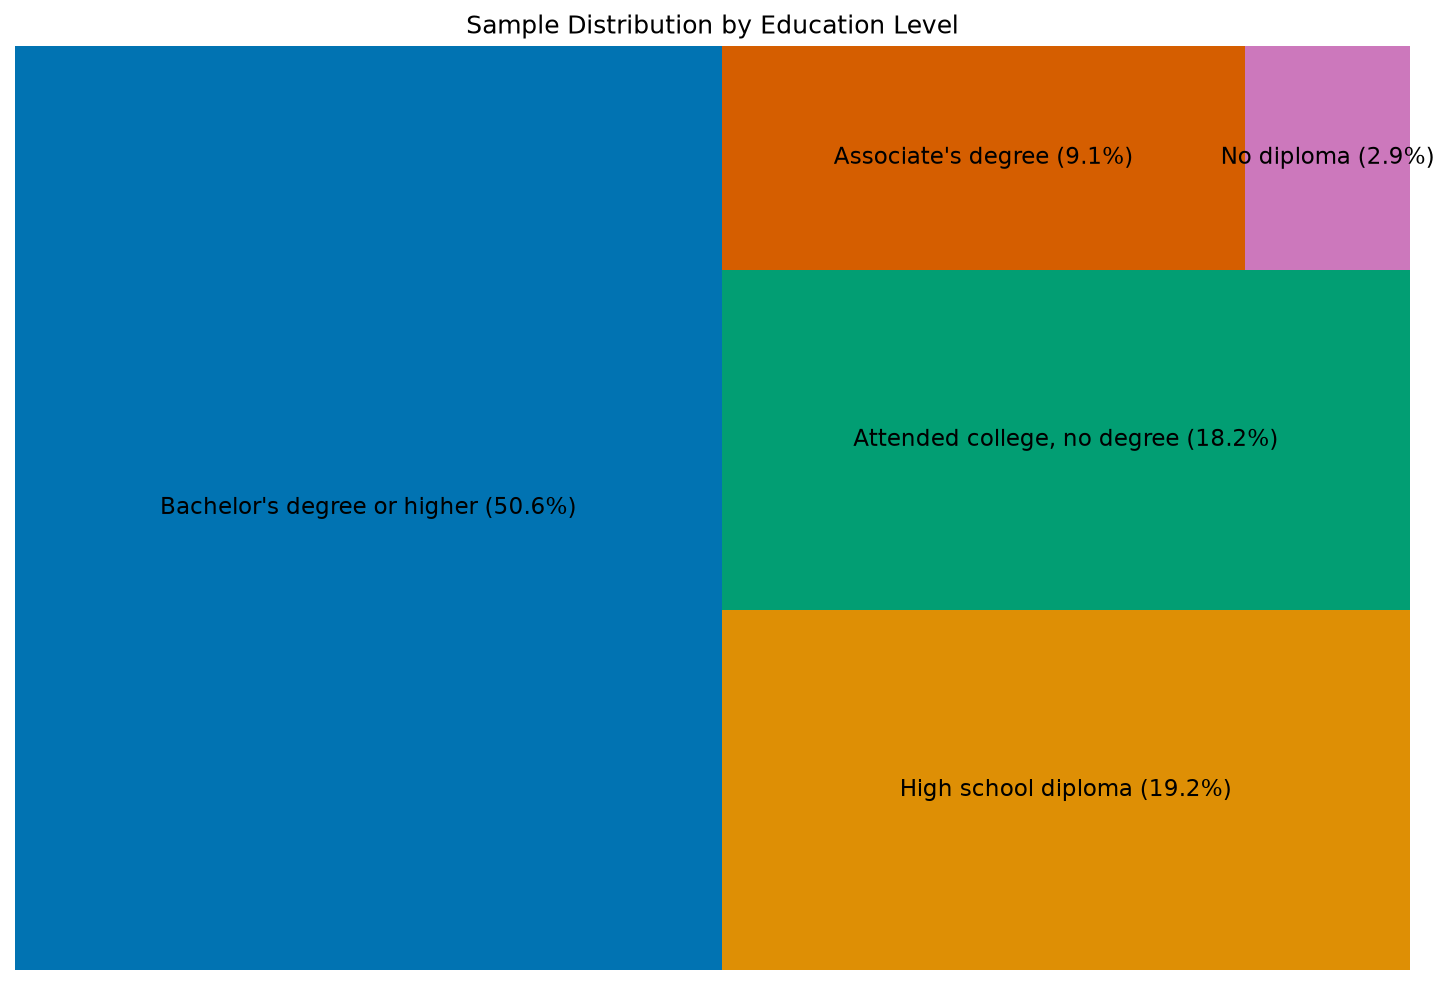

In [3]:
# --- Treemap: sample share by education group ---
edu = d["Education"].value_counts().reset_index()
edu.columns = ["Education", "Count"]
edu["Pct"] = edu["Count"] / edu["Count"].sum() * 100

plt.figure(figsize=(12, 8), dpi=150)
squarify.plot(
    sizes=edu["Pct"],
    label=[f"{r.Education} ({r.Pct:.1f}%)" for r in edu.itertuples()],
    color=sns.color_palette("colorblind", len(edu)),
    text_kwargs={"fontsize": 11},
)
plt.axis("off")
plt.title("Sample Distribution by Education Level")
plt.savefig("images/treemap_education.png", bbox_inches="tight")
plt.show()


**Figure 1.** Treemap of the filtered sample. Most workers hold a Bachelor's degree or higher; the "No diploma" group is the smallest, so comparisons for that group are less stable.

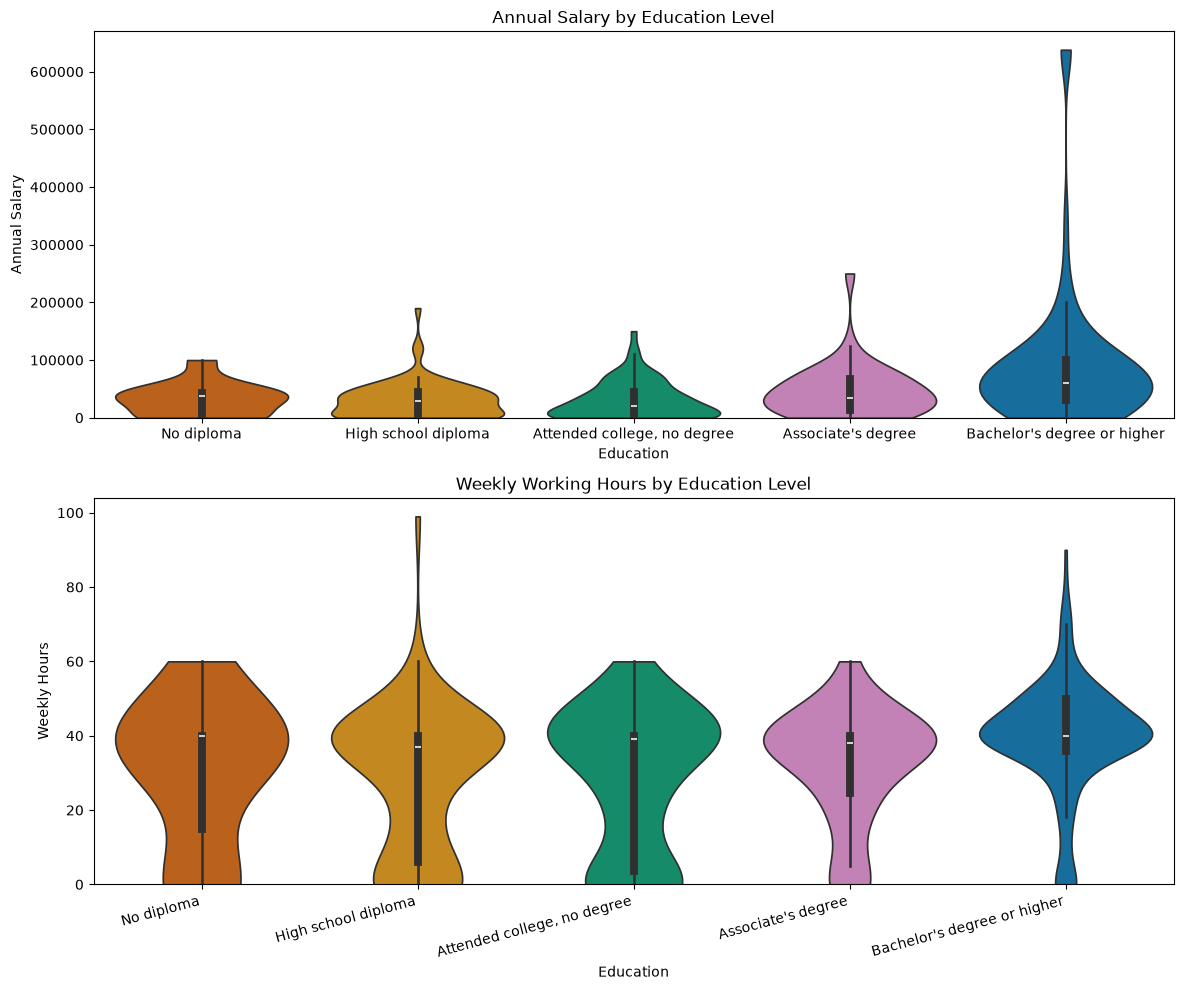

In [4]:
# --- Violin plots: salary and weekly hours by education group ---
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 10))

sns.violinplot(
    x="Education", y="Annual Salary", data=d, ax=axes[0],
    hue="Education", legend=False, palette="colorblind",
    order=order, cut=0,
)
axes[0].set_title("Annual Salary by Education Level")
axes[0].set_xlabel("Education")
axes[0].set_ylabel("Annual Salary")
axes[0].set_ylim(bottom=0)

sns.violinplot(
    x="Education", y="Weekly hours", data=d, ax=axes[1],
    hue="Education", legend=False, palette="colorblind",
    order=order, cut=0,
)
axes[1].set_title("Weekly Working Hours by Education Level")
axes[1].set_xlabel("Education")
axes[1].set_ylabel("Weekly Hours")
axes[1].set_ylim(bottom=0)

plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("images/violin_salary_hours.png", bbox_inches="tight")
plt.show()


## Key Findings
- Workers with a **Bachelor's degree or higher** have the highest salary distribution: median 61,000 and mean about 89,963, compared with the other four groups, whose medians fall between about 20,400 and 38,000.
- Salary does **not** increase monotonically with education: the "No diploma" median (38,000) is higher than the high-school and college-no-degree medians, but this group contains only 11 workers.
- Weekly working hours are similar across groups (median 37–40 hours); the data do not show a clear monotonic relationship between education and hours.

## Limitations
- This is observational data, so the plots show correlation, not causation. Age, industry, and location are not controlled for.
- The dataset contains zero salary values (65 rows) and zero hour values (54 rows); these were kept rather than separately coded.
- The filtered sample has 385 rows, and some education groups are small, so group comparisons are not equally reliable.
- The currency unit is not stated in the source file.